# 19 — Polarimetric capstone: the clear-cut seen by L-band and C-band

**Question:** which dual-pol parameters change most on the clear-cut between the dates before and
after the cut, relative to the unchanged control forest — and does L-band (NISAR) separate the cut
better than C-band (Sentinel-1)?

**Method.** For each sensor and parameter: change Δ = post − pre per pixel (40 m), then
separability of the cut pixels from the control pixels measured by the AUC (0.5 = no separation,
1 = perfect), with the moving-block bootstrap of the feasibility study for a confidence interval.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # training/notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "19"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
import h5py
from affine import Affine
from nisar_s1 import polarimetry as pol
from nisar_s1.grid import polygon_mask, read_geotiff, to_grid
from nisar_s1.optical import Raster
from nisar_s1.snap import dimap_band
from nisar_s1.stats import auc, block_bootstrap_auc
import geopandas as gpd
session = P.load_session(kit["session_file"], required=("gslc_subsets", "c2_looks"))
looks = tuple(session["c2_looks"])

In [2]:
def params(c):
    ha = pol.h_alpha_dual(c)
    return {"co (dB)": pol.to_db(c.c11), "cross (dB)": pol.to_db(c.c22), "H": ha["H"], "alpha": ha["alpha"],
            "DpRVI": pol.dprvi(c), "m": pol.degree_of_polarization(c)}

def nisar(path):
    with h5py.File(path) as h5:
        g = P.product_profile(h5).grids["frequencyA"]
        w = P.window_from_bounds(g, g.bounds)
        c = pol.c2_from_slc(P.read_layer(h5, g, "HH", w), P.read_layer(h5, g, "HV", w), looks)
    return params(c), Raster(c.c11, w.transform @ Affine.scale(looks[1], looks[0]), w.crs)

def s1(dim):
    b = {k: read_geotiff(dimap_band(dim, k)) for k in ("C11", "C22", "C12_real", "C12_imag")}
    c = pol.c2_from_elements(*(np.where(b[k].data == 0, np.nan, b[k].data) for k in ("C11", "C22", "C12_real", "C12_imag")))
    return params(c), b["C11"]

dims = sorted((Path(kit["data_dir"]) / "s1").glob("c2_*.dim"))
sensors = {}
for i, (name, fn, pair) in enumerate([("NISAR L-band (HH/HV)", nisar, session["gslc_subsets"][:2]),
                                      ("Sentinel-1 C-band (VV/VH)", s1, dims[:2])], 1):
    (pre, ref), (post, ref_post) = fn(pair[0]), fn(pair[1])
    # SNAP terrain correction may give the two dates slightly different extents (one row here):
    # bring "post" onto the "pre" grid (nearest neighbour, same 40 m pixels) before differencing
    post = {k: to_grid(Raster(v, ref_post.transform, ref_post.crs), ref, resampling="nearest").data for k, v in post.items()}
    sensors[name] = {"delta": {k: post[k] - pre[k] for k in pre}, "ref": ref}
    print(f"[{i}/2] {name}: grid {ref.data.shape}")

[1/2] NISAR L-band (HH/HV): grid (143, 155)
[2/2] Sentinel-1 C-band (VV/VH): grid (172, 175)


In [3]:
sites = gpd.read_file(kit["aoi"]["site_polygons"])
rows = []
for name, s in sensors.items():
    st = sites.to_crs(s["ref"].crs)
    cut = polygon_mask(list(st[st.role == "cut"].geometry), s["ref"])
    ctl = polygon_mask(list(st[st.role == "control"].geometry), s["ref"])
    for k, d in s["delta"].items():
        ok = np.isfinite(d)
        a, b = d[cut & ok], d[ctl & ok]
        sep = auc(a, b)
        lo, hi = block_bootstrap_auc(d, cut & ok, ctl & ok, block=2, n=300)
        rows.append({"sensor": name, "parameter": k, "n cut": a.size, "n control": b.size,
                     "median Δ cut": np.median(a), "median Δ control": np.median(b), "AUC": max(sep, 1 - sep),
                     "AUC 95% CI": f"{lo:.2f}–{hi:.2f}" if np.isfinite(lo) else "-"})
res = pd.DataFrame(rows).round(3); res

,sensor,parameter,n cut,n control,median Δ cut,median Δ control,AUC,AUC 95% CI
0,NISAR L-band (HH/HV),co (dB),16,142,-3.583,0.608,0.985,0.96–1.00
1,NISAR L-band (HH/HV),cross (dB),16,142,-4.255,0.344,0.975,0.94–1.00
2,NISAR L-band (HH/HV),H,16,142,-0.024,-0.019,0.593,0.51–0.72
3,NISAR L-band (HH/HV),alpha,16,142,-1.717,-1.284,0.531,0.50–0.70
4,NISAR L-band (HH/HV),DpRVI,16,142,-0.025,-0.022,0.585,0.50–0.71
5,NISAR L-band (HH/HV),m,16,142,0.023,0.022,0.584,0.51–0.70
6,Sentinel-1 C-band (VV/VH),co (dB),16,141,-2.180,0.771,0.903,0.84–0.97
7,Sentinel-1 C-band (VV/VH),cross (dB),16,141,-2.181,0.923,0.972,0.94–1.00
8,Sentinel-1 C-band (VV/VH),H,16,141,0.021,0.014,0.516,0.50–0.68
9,Sentinel-1 C-band (VV/VH),alpha,16,141,-1.240,0.384,0.548,0.50–0.70


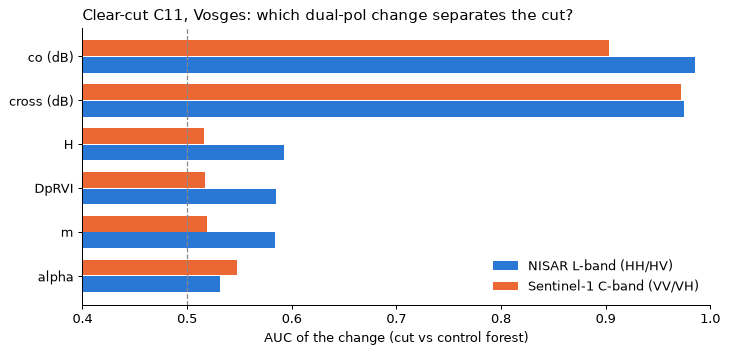

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
pv = res.pivot(index="parameter", columns="sensor", values="AUC").sort_values("NISAR L-band (HH/HV)")
y = np.arange(len(pv))
for j, (col, c) in enumerate(zip(pv.columns, ["#2a78d6", "#eb6834"])):
    ax.barh(y + (j - 0.5) * 0.38, pv[col], height=0.36, color=c, label=col)
ax.set_yticks(y, pv.index); ax.axvline(0.5, color="#888888", lw=1, ls="--")
ax.set_xlim(0.4, 1.0); ax.set_xlabel("AUC of the change (cut vs control forest)")
ax.legend(frameon=False, loc="lower right"); ax.set_title("Clear-cut C11, Vosges: which dual-pol change separates the cut?", loc="left")
fig.savefig(OUT / "19_auc.png", dpi=130, bbox_inches="tight"); plt.show()

## What this run shows (and its limits)
* **The powers carry the signal.** The co- and cross-pol power drops on the cut separate it from
  the control almost perfectly at both bands (AUC ≈ 0.97–0.99 at L-band, 0.90–0.97 at C-band). The
  drop is larger at L-band (cross-pol ≈ −4.3 dB vs ≈ −2.2 dB at C-band, control ≈ 0): L-band sees
  the loss of trunks and branches, C-band mostly the loss of the canopy.
* **The normalized dual-pol parameters do not.** H, ᾱ, DpRVI and m change by a few hundredths
  (AUC 0.52–0.59, intervals touching 0.5). They describe the *balance* between co- and cross-pol,
  and a fresh clear-cut (stumps, slash, rough soil) still depolarizes: both powers fall together.
  The complex GSLC (13 GB per date) therefore adds nothing for this question over the GCOV powers.
* At 40 m (32 looks) the speckle is low enough for C-band to separate a fresh 2.4 ha cut too; the
  feasibility study, at 20 m and over several months, found L-band clearly ahead (persistence of
  the contrast, notebook 11).
* One cut, ~16 pixels at 40 m: wide confidence intervals, one site, one season. The **method**
  transfers (other sites, Morvan; ROSE-L later), the numbers have to be re-established there.

In [5]:
res.to_csv(OUT / "19_auc_table.csv", index=False); print(OUT / "19_auc_table.csv")

/media/dell/Transcend1/nisar_data/kit/outputs/19/19_auc_table.csv


In [6]:
checks = {
    "both sensors processed": len(sensors) == 2,
    "cut sampled at both bands": (res['n cut'] > 5).all(),
    "AUC table written": (OUT / "19_auc_table.csv").exists(),
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 19 STATUS: PASS")

  [x] both sensors processed
  [x] cut sampled at both bands
  [x] AUC table written
Module 19 STATUS: PASS
